# Machine Learning Lab: Model Evaluation and Hyperparameter Tuning
## Raisin Dataset

### Aim
To train and evaluate classification models on the Raisin dataset, then improve their performance through cross-validation, Grid Search, and Randomized Search.

### Objectives
1. Inspect the dataset and prepare its numerical features and categorical target.
2. Divide the observations into stratified training and testing subsets.
3. Evaluate classifiers using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
4. Estimate model performance using stratified cross-validation.
5. Tune model hyperparameters using GridSearchCV and RandomizedSearchCV.
6. Compare baseline and tuned models on a held-out test set.

### Dataset overview
The supplied workbook contains 900 raisin observations. Each observation has seven numerical measurements and a class label identifying one of two raisin varieties: Kecimen or Besni. The class column is the prediction target. It is not included among the input features.

The notebook uses a fixed random seed and pipelines for scaled models. Scaling is fitted inside each cross-validation fold, which prevents information from the validation fold from leaking into the training process.

## 1. Import libraries
The libraries below support data inspection, plotting, model training, evaluation, cross-validation, and parameter search. The classifiers are placed in scikit-learn pipelines where necessary so that preprocessing is repeated correctly within each training fold.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import randint
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, RandomizedSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay,
    classification_report
)

RANDOM_STATE = 42
plt.rcParams.update({"figure.figsize": (8, 4.8), "font.size": 10})

## 2. Load the supplied workbook
The workbook includes the raisin measurements in the `Raisin_Grains_Dataset` sheet. The separate citation-request sheet is metadata and is not part of the modelling table. The target column is named `Class`.

In [2]:
file_path = "Raisin_Dataset.xlsx"
df = pd.read_excel(file_path, sheet_name="Raisin_Grains_Dataset")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("\nFirst five observations:")
print(df.head().to_string(index=False))
print("\nColumn names:", df.columns.tolist())

Dataset loaded successfully.
Shape: (900, 8)

First five observations:
 Area  MajorAxisLength  MinorAxisLength  Eccentricity  ConvexArea   Extent  Perimeter   Class
87524       442.246011       253.291155      0.819738       90546 0.758651   1184.040 Kecimen
75166       406.690687       243.032436      0.801805       78789 0.684130   1121.786 Kecimen
90856       442.267048       266.328318      0.798354       93717 0.637613   1208.575 Kecimen
45928       286.540559       208.760042      0.684989       47336 0.699599    844.162 Kecimen
79408       352.190770       290.827533      0.564011       81463 0.792772   1073.251 Kecimen

Column names: ['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter', 'Class']


## 3. Inspect data types and data quality
This step checks each column's data type, the number of missing values, and the number of duplicate records. The feature columns should be numerical, while `Class` should be categorical. Missing values or duplicate rows would need to be handled before modelling.

In [3]:
print("Data types:")
print(df.dtypes.to_string())
print("\nMissing values by column:")
print(df.isnull().sum().to_string())
print("\nTotal missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nClass distribution:")
print(df["Class"].value_counts().to_string())

Data types:
Area                 int64
MajorAxisLength    float64
MinorAxisLength    float64
Eccentricity       float64
ConvexArea           int64
Extent             float64
Perimeter          float64
Class               object

Missing values by column:
Area               0
MajorAxisLength    0
MinorAxisLength    0
Eccentricity       0
ConvexArea         0
Extent             0
Perimeter          0
Class              0

Total missing values: 0
Duplicate rows: 0

Class distribution:
Class
Kecimen    450
Besni      450


## 4. Summary statistics and class distribution
Descriptive statistics provide a quick view of the measurement ranges and variability. The class-count chart checks whether the two target categories are represented equally. The Raisin dataset is a binary classification problem.

Numerical features: ['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter']

Summary statistics:
            Area  MajorAxisLength  MinorAxisLength  Eccentricity  ConvexArea  Extent  Perimeter
count     900.00           900.00           900.00        900.00      900.00  900.00     900.00
mean    87804.13           430.93           254.49          0.78    91186.09    0.70    1165.91
std     39002.11           116.04            49.99          0.09    40769.29    0.05     273.76
min     25387.00           225.63           143.71          0.35    26139.00    0.38     619.07
25%     59348.00           345.44           219.11          0.74    61513.25    0.67     966.41
50%     78902.00           407.80           247.85          0.80    81651.00    0.71    1119.51
75%    105028.25           494.19           279.89          0.84   108375.75    0.73    1308.39
max    235047.00           997.29           492.28          0.96   278217.00    0.84    269

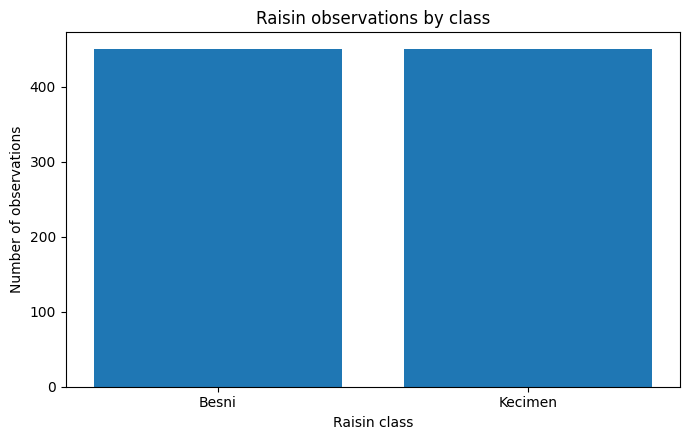

In [4]:
feature_cols = df.select_dtypes(include=np.number).columns.tolist()
X = df[feature_cols].copy()
y_text = df["Class"].astype(str)

print("Numerical features:", feature_cols)
print("\nSummary statistics:")
print(X.describe().round(2).to_string())

class_counts = y_text.value_counts().sort_index()
plt.figure(figsize=(7, 4.5))
plt.bar(class_counts.index, class_counts.values)
plt.title("Raisin observations by class")
plt.xlabel("Raisin class")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

## 5. Encode the target and split the data
The class names are converted into numeric labels for evaluation. `LabelEncoder` stores the mapping, which is printed below. A stratified 80:20 split preserves the class proportions in both subsets. The test data is kept aside until final model evaluation.

In [5]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
class_mapping = {name: int(label_encoder.transform([name])[0]) for name in label_encoder.classes_}
print("Target encoding:", class_mapping)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training class counts:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Testing class counts:", dict(zip(*np.unique(y_test, return_counts=True))))

Target encoding: {'Besni': 0, 'Kecimen': 1}
Training rows: 720
Testing rows: 180
Training class counts: {np.int64(0): np.int64(360), np.int64(1): np.int64(360)}
Testing class counts: {np.int64(0): np.int64(90), np.int64(1): np.int64(90)}


## 6. Define the evaluation measures
Accuracy is the proportion of correct predictions. Precision measures how many predicted positive cases are correct. Recall measures how many actual positive cases are found. F1-score is the harmonic mean of Precision and Recall. ROC-AUC measures how well the model separates the two classes across classification thresholds.

In this experiment, the positive class is the second class in the printed encoding. All reported Precision, Recall, and F1 values use that same positive-class definition.

In [6]:
positive_label = 1
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Positive class:", label_encoder.inverse_transform([positive_label])[0])
print("Cross-validation:", "5-fold StratifiedKFold")

Positive class: Kecimen
Cross-validation: 5-fold StratifiedKFold


## 7. Create baseline classification models
Five commonly used classifiers are selected: Logistic Regression, K-Nearest Neighbors, Support Vector Machine, Decision Tree, and Random Forest. Standardization is included for Logistic Regression, KNN, and SVM because these algorithms are sensitive to feature scale. Tree models are used without scaling.

In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier())
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(probability=True, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
}
print("Models prepared:", ", ".join(models.keys()))

Models prepared: Logistic Regression, KNN, SVM, Decision Tree, Random Forest


## 8. Baseline evaluation on the test set
Each baseline model is fitted using the training subset and evaluated on the same held-out test subset. The table reports all five required evaluation measures. Probabilities are used to calculate ROC-AUC rather than using hard class predictions.

In [8]:
def calculate_metrics(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)[:, 1]
    return {
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision": precision_score(y_eval, predictions, pos_label=positive_label, zero_division=0),
        "Recall": recall_score(y_eval, predictions, pos_label=positive_label, zero_division=0),
        "F1-score": f1_score(y_eval, predictions, pos_label=positive_label, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, probabilities)
    }

baseline_test = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    baseline_test[name] = calculate_metrics(model, X_test, y_test)

baseline_test_df = pd.DataFrame(baseline_test).T
print(baseline_test_df.round(4).to_string())

                     Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.8889     0.8500  0.9444    0.8947   0.9185
KNN                    0.8611     0.8095  0.9444    0.8718   0.8996
SVM                    0.8778     0.8269  0.9556    0.8866   0.9102
Decision Tree          0.8444     0.8039  0.9111    0.8542   0.8444
Random Forest          0.8667     0.8173  0.9444    0.8763   0.9211


## 9. Compare baseline test metrics
The grouped bar chart makes it possible to compare the five evaluation measures across all baseline models. Differences among scores can reveal whether a model is accurate overall but weaker at identifying the positive class.

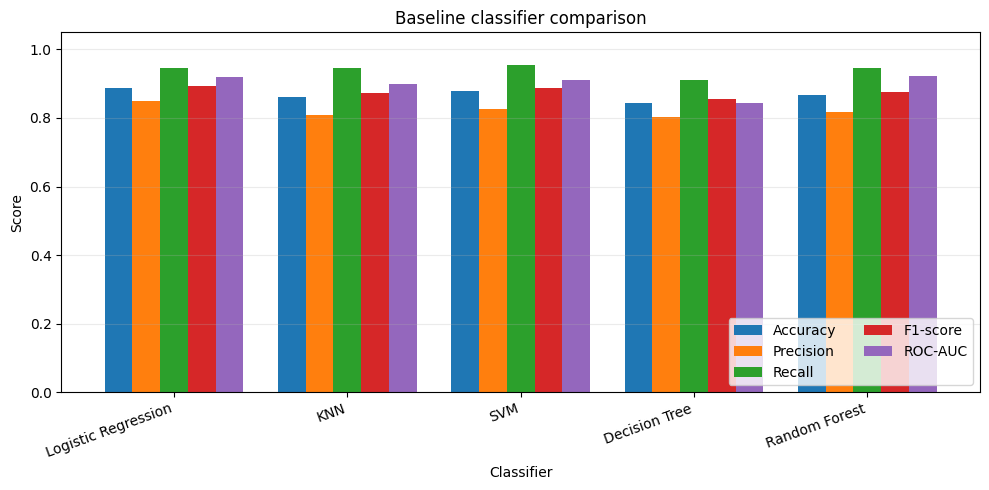

In [9]:
ax = baseline_test_df.plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05), width=0.8)
ax.set_title("Baseline classifier comparison")
ax.set_xlabel("Classifier")
ax.set_ylabel("Score")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.legend(loc="lower right", ncol=2)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Cross-validation on baseline models
A single train-test split can produce results that depend on how the data happened to be divided. Five-fold stratified cross-validation repeats training and validation across five folds while preserving class proportions. The table reports the mean and standard deviation for each metric. Cross-validation uses only the training subset; the held-out test set remains untouched.

In [10]:
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"Model": name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric.upper()} mean"] = values.mean()
        row[f"{metric.upper()} std"] = values.std()
    cv_rows.append(row)

cv_results_df = pd.DataFrame(cv_rows).set_index("Model")
print(cv_results_df.round(4).to_string())

                     ACCURACY mean  ACCURACY std  PRECISION mean  PRECISION std  RECALL mean  RECALL std  F1 mean  F1 std  ROC_AUC mean  ROC_AUC std
Model                                                                                                                                               
Logistic Regression         0.8667        0.0193          0.8580         0.0314       0.8806      0.0111   0.8688  0.0164        0.9310       0.0125
KNN                         0.8472        0.0152          0.8326         0.0299       0.8722      0.0322   0.8510  0.0134        0.9091       0.0202
SVM                         0.8597        0.0183          0.8330         0.0334       0.9028      0.0124   0.8659  0.0138        0.9238       0.0180
Decision Tree               0.8056        0.0170          0.8086         0.0284       0.8028      0.0269   0.8050  0.0158        0.8056       0.0170
Random Forest               0.8569        0.0179          0.8443         0.0312       0.8778      0.0297  

## 11. Visualize cross-validation F1-score
The plot compares mean F1-score across the five validation folds. Error bars show one standard deviation, providing a simple indication of variation between folds. A higher mean score is desirable, while a smaller spread indicates more consistent results across the folds.

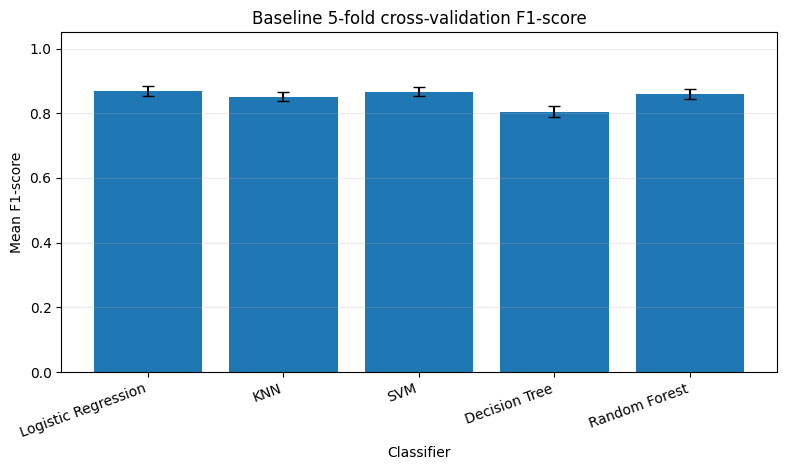

In [11]:
f1_means = cv_results_df["F1 mean"]
f1_stds = cv_results_df["F1 std"]
plt.figure(figsize=(8, 4.8))
plt.bar(f1_means.index, f1_means.values, yerr=f1_stds.values, capsize=4)
plt.title("Baseline 5-fold cross-validation F1-score")
plt.xlabel("Classifier")
plt.ylabel("Mean F1-score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 12. Hyperparameter tuning with GridSearchCV
Grid Search evaluates every supplied parameter combination using cross-validation. Separate search spaces are defined for each classifier. F1-score is used as the selection metric so that the search considers both Precision and Recall. The best parameter combination is then refitted on the complete training subset.

In [12]:
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.1, 1.0, 10.0],
        "classifier__class_weight": [None, "balanced"]
    },
    "KNN": {
        "classifier__n_neighbors": [3, 5, 7, 9, 11],
        "classifier__weights": ["uniform", "distance"],
        "classifier__p": [1, 2]
    },
    "SVM": {
        "classifier__C": [0.1, 1.0, 10.0],
        "classifier__gamma": ["scale", "auto"]
    },
    "Decision Tree": {
        "criterion": ["gini", "entropy"],
        "max_depth": [None, 5, 10, 20],
        "min_samples_leaf": [1, 2, 4]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2]
    }
}

print("Grid Search parameter combinations:")
for name, grid in param_grids.items():
    count = int(np.prod([len(values) for values in grid.values()]))
    print(f"{name}: {count} combinations")

Grid Search parameter combinations:
Logistic Regression: 6 combinations
KNN: 20 combinations
SVM: 6 combinations
Decision Tree: 24 combinations
Random Forest: 24 combinations


In [13]:
grid_searches = {}
grid_rows = []
for name, model in models.items():
    search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )
    search.fit(X_train, y_train)
    grid_searches[name] = search
    grid_rows.append({
        "Model": name,
        "Best CV F1": search.best_score_,
        "Best parameters": str(search.best_params_)
    })

grid_results_df = pd.DataFrame(grid_rows).set_index("Model")
print(grid_results_df.round(4).to_string())

                     Best CV F1                                                                          Best parameters
Model                                                                                                                   
Logistic Regression      0.8707                                 {'classifier__C': 0.1, 'classifier__class_weight': None}
KNN                      0.8622     {'classifier__n_neighbors': 7, 'classifier__p': 1, 'classifier__weights': 'uniform'}
SVM                      0.8724                                     {'classifier__C': 0.1, 'classifier__gamma': 'scale'}
Decision Tree            0.8447                          {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1}
Random Forest            0.8657  {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}


## 13. RandomizedSearchCV for Random Forest
Randomized Search samples a fixed number of parameter combinations from specified distributions instead of checking every possible combination. It can explore a broader parameter space with a controlled number of model fits. Here it is applied to Random Forest to compare this search strategy with the Random Forest Grid Search above.

In [14]:
from scipy.stats import randint

rf_random_space = {
    "n_estimators": randint(80, 301),
    "max_depth": [None, 5, 10, 15, 20, 25],
    "min_samples_split": randint(2, 10),
    "min_samples_leaf": randint(1, 5),
    "max_features": ["sqrt", "log2", None]
}

rf_random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=rf_random_space,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True
)
rf_random_search.fit(X_train, y_train)
print("Randomized Search best CV F1:", round(rf_random_search.best_score_, 4))
print("Randomized Search best parameters:")
print(rf_random_search.best_params_)

Randomized Search best CV F1: 0.8687
Randomized Search best parameters:
{'max_depth': 25, 'max_features': None, 'min_samples_leaf': 4, 'min_samples_split': 8, 'n_estimators': 143}


## 14. Compare Grid Search and Randomized Search
Both search methods optimize the same Random Forest F1-score objective, but they explore different parameter selections. Grid Search evaluates the defined combinations exhaustively. Randomized Search samples 20 combinations from a wider range. Their best cross-validation F1-scores are compared below.

    Search method  Best CV F1-score
      Grid Search            0.8657
Randomized Search            0.8687


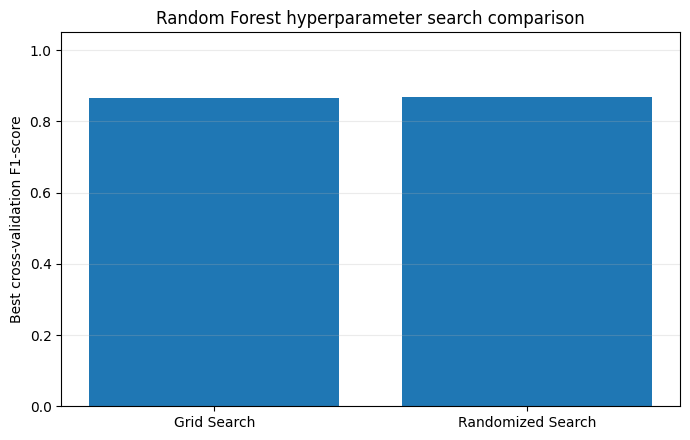

In [15]:
rf_grid_score = grid_searches["Random Forest"].best_score_
search_comparison = pd.DataFrame({
    "Search method": ["Grid Search", "Randomized Search"],
    "Best CV F1-score": [rf_grid_score, rf_random_search.best_score_]
})
print(search_comparison.round(4).to_string(index=False))

plt.figure(figsize=(7, 4.5))
plt.bar(search_comparison["Search method"], search_comparison["Best CV F1-score"])
plt.title("Random Forest hyperparameter search comparison")
plt.ylabel("Best cross-validation F1-score")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 15. Evaluate tuned models on the held-out test data
The best estimator from each Grid Search is evaluated on the test subset. The Randomized Search Random Forest is included as a separate candidate. These scores provide a final comparison after the tuning process. The test data has not been used to select hyperparameters.

In [16]:
tuned_candidates = {
    f"{name} (Grid)": search.best_estimator_
    for name, search in grid_searches.items()
}
tuned_candidates["Random Forest (Randomized)"] = rf_random_search.best_estimator_

tuned_test = {}
for name, model in tuned_candidates.items():
    tuned_test[name] = calculate_metrics(model, X_test, y_test)

tuned_test_df = pd.DataFrame(tuned_test).T
print(tuned_test_df.round(4).to_string())

                            Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression (Grid)    0.8778     0.8400  0.9333    0.8842   0.9136
KNN (Grid)                    0.8778     0.8269  0.9556    0.8866   0.9211
SVM (Grid)                    0.8722     0.8252  0.9444    0.8808   0.9154
Decision Tree (Grid)          0.8500     0.8058  0.9222    0.8601   0.8788
Random Forest (Grid)          0.8722     0.8190  0.9556    0.8821   0.9209
Random Forest (Randomized)    0.8778     0.8269  0.9556    0.8866   0.9223


## 16. Baseline and tuned performance comparison
The next table places baseline test performance beside the tuned model results. The same five metrics are used for both groups. This makes changes in overall correctness, positive-class identification, and class separation easier to inspect.

In [17]:
comparison_rows = []
for name in models:
    baseline = baseline_test_df.loc[name]
    tuned_name = f"{name} (Grid)"
    tuned = tuned_test_df.loc[tuned_name]
    for metric in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]:
        comparison_rows.append({
            "Model": name,
            "Metric": metric,
            "Baseline": baseline[metric],
            "Tuned": tuned[metric],
            "Change": tuned[metric] - baseline[metric]
        })
comparison_df = pd.DataFrame(comparison_rows)
print(comparison_df.round(4).to_string(index=False))

              Model    Metric  Baseline  Tuned  Change
Logistic Regression  Accuracy    0.8889 0.8778 -0.0111
Logistic Regression Precision    0.8500 0.8400 -0.0100
Logistic Regression    Recall    0.9444 0.9333 -0.0111
Logistic Regression  F1-score    0.8947 0.8842 -0.0105
Logistic Regression   ROC-AUC    0.9185 0.9136 -0.0049
                KNN  Accuracy    0.8611 0.8778  0.0167
                KNN Precision    0.8095 0.8269  0.0174
                KNN    Recall    0.9444 0.9556  0.0111
                KNN  F1-score    0.8718 0.8866  0.0148
                KNN   ROC-AUC    0.8996 0.9211  0.0215
                SVM  Accuracy    0.8778 0.8722 -0.0056
                SVM Precision    0.8269 0.8252 -0.0017
                SVM    Recall    0.9556 0.9444 -0.0111
                SVM  F1-score    0.8866 0.8808 -0.0058
                SVM   ROC-AUC    0.9102 0.9154  0.0052
      Decision Tree  Accuracy    0.8444 0.8500  0.0056
      Decision Tree Precision    0.8039 0.8058  0.0019
      Deci

## 17. Select the strongest tuned candidate
The candidate with the highest cross-validation F1-score is selected. Grid Search candidates are ranked using their recorded best cross-validation scores. The Randomized Search Random Forest is also considered. The selected estimator is then examined using its held-out test metrics.

In [18]:
candidate_cv_scores = {
    f"{name} (Grid)": search.best_score_
    for name, search in grid_searches.items()
}
candidate_cv_scores["Random Forest (Randomized)"] = rf_random_search.best_score_

best_candidate_name = max(candidate_cv_scores, key=candidate_cv_scores.get)
best_model = tuned_candidates[best_candidate_name]
print("Selected tuned candidate:", best_candidate_name)
print("Best cross-validation F1-score:", round(candidate_cv_scores[best_candidate_name], 4))
print("Held-out test metrics:")
print(pd.Series(tuned_test[best_candidate_name]).round(4).to_string())

Selected tuned candidate: SVM (Grid)
Best cross-validation F1-score: 0.8724
Held-out test metrics:
Accuracy     0.8722
Precision    0.8252
Recall       0.9444
F1-score     0.8808
ROC-AUC      0.9154


## 18. ROC curves for tuned candidates
ROC curves display the trade-off between the true positive rate and false positive rate across probability thresholds. The area under each curve is also shown in the legend. A curve closer to the upper-left corner generally indicates stronger separation between the two raisin classes.

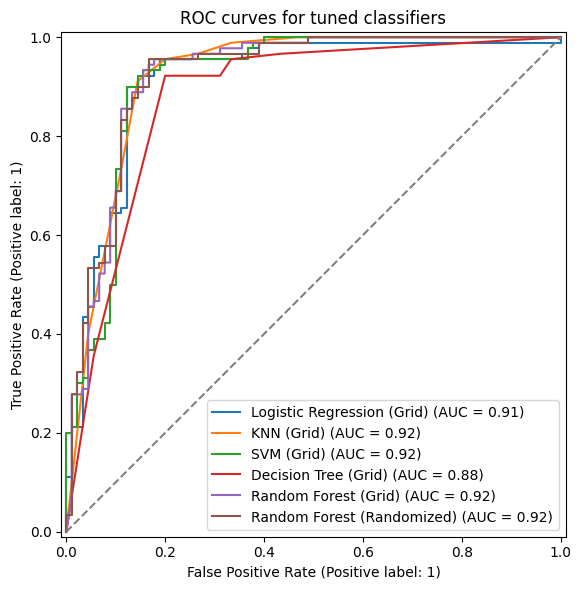

In [19]:
plt.figure(figsize=(8, 6))
for name, model in tuned_candidates.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random baseline")
plt.title("ROC curves for tuned classifiers")
plt.tight_layout()
plt.show()

## 19. Confusion matrix and classification report
The confusion matrix for the selected tuned model shows correct and incorrect predictions for both classes. The classification report gives per-class Precision, Recall, and F1-score. This complements the aggregate metrics reported earlier.

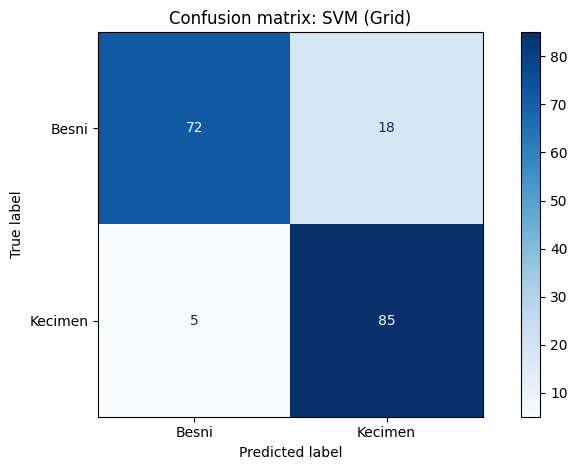

              precision    recall  f1-score   support

       Besni     0.9351    0.8000    0.8623        90
     Kecimen     0.8252    0.9444    0.8808        90

    accuracy                         0.8722       180
   macro avg     0.8802    0.8722    0.8716       180
weighted avg     0.8802    0.8722    0.8716       180



In [20]:
best_predictions = best_model.predict(X_test)
class_names = label_encoder.classes_
ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=class_names,
    cmap="Blues",
    values_format="d"
)
plt.title(f"Confusion matrix: {best_candidate_name}")
plt.tight_layout()
plt.show()

print(classification_report(y_test, best_predictions, target_names=class_names, digits=4))

## 20. Key findings
The results should be interpreted using both the held-out test metrics and cross-validation scores. Grid Search and Randomized Search offer different ways to locate useful hyperparameter settings. A higher cross-validation score is not a guarantee of identical improvement on unseen data, which is why the test subset is evaluated separately.

In [21]:
baseline_best = baseline_test_df["F1-score"].idxmax()
tuned_best_test = tuned_test_df["F1-score"].idxmax()
print("Best baseline by test F1:", baseline_best, round(baseline_test_df.loc[baseline_best, "F1-score"], 4))
print("Best tuned candidate by test F1:", tuned_best_test, round(tuned_test_df.loc[tuned_best_test, "F1-score"], 4))
print("Selected candidate by cross-validation:", best_candidate_name)
print("Selected candidate test ROC-AUC:", round(tuned_test[best_candidate_name]["ROC-AUC"], 4))

Best baseline by test F1: Logistic Regression 0.8947
Best tuned candidate by test F1: KNN (Grid) 0.8866
Selected candidate by cross-validation: SVM (Grid)
Selected candidate test ROC-AUC: 0.9154


## 21. Conclusion and learning outcomes
The Raisin dataset was used to train five classification models. Their performance was assessed with Accuracy, Precision, Recall, F1-score, and ROC-AUC. Five-fold stratified cross-validation provided a more stable estimate of model performance. Grid Search and Randomized Search were then used to tune model parameters, and the selected models were checked on a held-out test set.

### Learning outcomes
- Compare common classification algorithms using multiple evaluation measures.
- Apply stratified cross-validation without using the test set for tuning.
- Use GridSearchCV and RandomizedSearchCV to find useful parameter settings.
- Interpret confusion matrices and ROC curves alongside numerical scores.

**Dataset:** `Raisin_Dataset.xlsx`, worksheet `Raisin_Grains_Dataset`. The target variable is `Class`.